In [31]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

from gprm import ReconstructionModel
from ptt import separate_ridge_transform_segments

import plate_driver as pdriver

%load_ext autoreload
%autoreload 2

M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')
M2016.add_continent_polygons('/Applications/GPlates-2.0.0/SampleData/FeatureCollections/ContinentalPolygons/Matthews_etal_GPC_2016_ContinentalPolygons.gpmlz')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}
#forces = {'ridge_push':1}

    
results = []    

for reconstruction_time in np.arange(10.,400.,10.):
    
    snapshot = M2016.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)
    
    results.append((reconstruction_time,result))
    
    

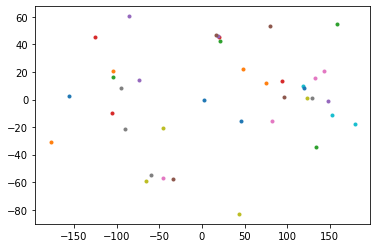

In [13]:
for result in results:
        
    plt.figure()
    for point in list(zip(*result[1]))[1]:
        plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], '.')
        
    plt.show()
    break
    


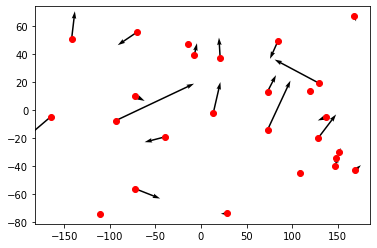

In [14]:
for result in results[5:6]:
    
    plt.figure()
    for point,vel in zip(list(zip(*result[1]))[1],
                         list(zip(*result[1]))[4]):
        if vel is not None:
            plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], 'ro')
            plt.quiver(point.to_lat_lon()[1],
                       point.to_lat_lon()[0],
                       vel.get_y(),
                       vel.get_x(),
                       color='k', units='xy', scale=0.02, width=1.5)
    break

In [16]:
target_plate_id = 301
reconstruction_time = 10.

snapshot = M2016.plate_snapshot(reconstruction_time)

forces = {'slab_pull': 1}
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces)
    
print(pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon())

forces = {'slab_suction': 1}
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces)
    
print(pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon())


(57.10020788762763, 123.35880402477936)
(1.2264785613321652, 165.58498307602963)


unable to plot vector for plate 925
unable to plot vector for plate 923


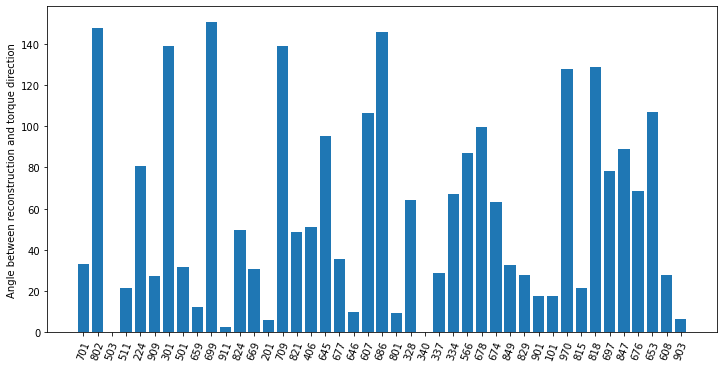

In [18]:
reconstruction_time = 0.
forces = {'slab_pull': 1,'slab_suction': 0.25, 'ridge_push':0.1}
#forces = {'ridge_push': 1}

snapshot = M2016.plate_snapshot(reconstruction_time)

result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

plate_ids = []
angles = []

for res in result:
    if res[4] is not None:
        try:
            angle = pygplates.Vector3D.angle_between(res[4],res[6])
            plate_ids.append(res[0])
            angles.append(np.degrees(angle))
        except:
            print('unable to plot vector for plate %d' % res[0])
    
    
width = 0.8
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(np.arange(len(angles)),angles)
ax.set_xticks(np.arange(len(angles)))
ax.set_xticklabels(plate_ids,rotation=70)
plt.ylabel('Angle between reconstruction and torque direction')
plt.show()
        

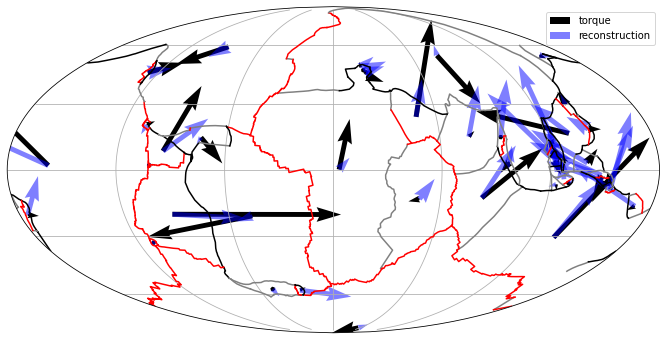

In [20]:
plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Mollweide())

for boundary in snapshot.resolved_topological_sections:
    shared_sub_segments = boundary.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        if shared_sub_segment.get_resolved_feature().get_geometry() is not None:
            if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
                boundary_color = 'black'
            elif shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_mid_ocean_ridge:
                boundary_color = 'red'
            else:
                boundary_color = 'gray'
            ax.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                    shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],
                    transform=ccrs.Geodetic(), color=boundary_color)


# plot the predicted velocities
x = []; y = []; u = []; v = []
for point,vel in zip(list(zip(*result))[1],
                     list(zip(*result))[4]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='black', label='torque')

# plot velocities according to the reconstruction
x = []; y = []; u = []; v = []
for point,vel in zip(list(zip(*result))[1],
                     list(zip(*result))[6]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='blue', alpha=0.5, label='reconstruction')

ax.set_global()
ax.gridlines()
plt.legend()
plt.show()


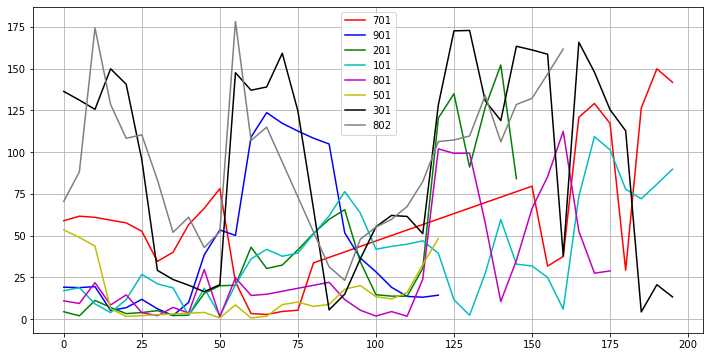

In [23]:
angle_701 = []; angle_901 = []; angle_201 = []; angle_101 = []; angle_801 = []; angle_501 = []; angle_301 = []; angle_802 = []

delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}

time_list = np.arange(0.,200.,5.)

for reconstruction_time in time_list:

    snapshot = M2016.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

    plate_ids = []
    angles = []

    for res in result:
        if res[4] is not None:
            if res[0]==701:
                angle_701.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==901:
                angle_901.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==201:
                angle_201.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==101:
                angle_101.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==801:
                angle_801.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==501:
                angle_501.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==301:
                angle_301.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==802:
                angle_802.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))

plt.figure(figsize=(12,6))
plt.plot(list(zip(*angle_701))[0],np.degrees(list(zip(*angle_701))[1]),'r', label=701)
plt.plot(list(zip(*angle_901))[0],np.degrees(list(zip(*angle_901))[1]),'b', label=901)
plt.plot(list(zip(*angle_201))[0],np.degrees(list(zip(*angle_201))[1]),'g', label=201)
plt.plot(list(zip(*angle_101))[0],np.degrees(list(zip(*angle_101))[1]),'c', label=101)
plt.plot(list(zip(*angle_801))[0],np.degrees(list(zip(*angle_801))[1]),'m', label=801)
plt.plot(list(zip(*angle_501))[0],np.degrees(list(zip(*angle_501))[1]),'y', label=501)
plt.plot(list(zip(*angle_301))[0],np.degrees(list(zip(*angle_301))[1]),'k', label=301)
plt.plot(list(zip(*angle_802))[0],np.degrees(list(zip(*angle_802))[1]),'grey', label=802)

plt.grid()
plt.legend()
                

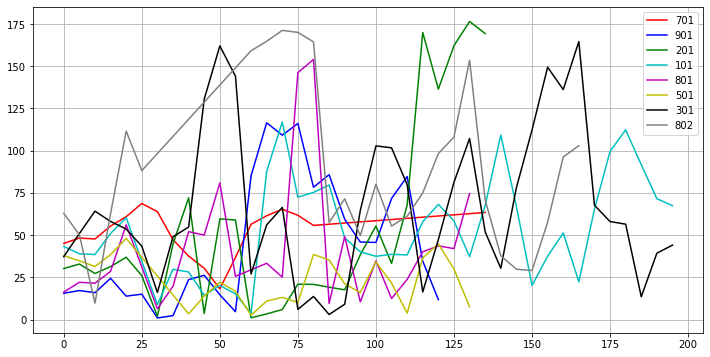

In [25]:
VDM = ReconstructionModel('VDM')
VDM.add_rotation_model('/Users/simon/Data/EByteSVN/EByteDeformingModels/Shephard_etal_2013_ESR/GPlates/Shephard_etal_ESR2013_Global_EarthByte_2013_VanDerMeer.rot')
VDM.add_static_polygons('/Users/simon/Data/EByteSVN/EByteDeformingModels/Shephard_etal_2013_ESR/GPlates/Shephard_etal_ESR2013_Global_staticpolygons.gpml')
VDM.add_dynamic_polygons('/Users/simon/Data/EByteSVN/EByteDeformingModels/Shephard_etal_2013_ESR/GPlates/Shephard_etal_ESR2013_Global_EarthByte_2013.gpml')

angle_701 = []; angle_901 = []; angle_201 = []; angle_101 = []; angle_801 = []; angle_501 = []; angle_301 = []; angle_802 = []

delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}

time_list = np.arange(0.,200.,5.)

for reconstruction_time in time_list:

    snapshot = VDM.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

    plate_ids = []
    angles = []

    for res in result:
        if res[4] is not None:
            if res[0]==701:
                angle_701.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==901:
                angle_901.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==201:
                angle_201.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==101:
                angle_101.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==801:
                angle_801.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==501:
                angle_501.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==301:
                angle_301.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==802:
                angle_802.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))

plt.figure(figsize=(12,6))
plt.plot(list(zip(*angle_701))[0],np.degrees(list(zip(*angle_701))[1]),'r', label=701)
plt.plot(list(zip(*angle_901))[0],np.degrees(list(zip(*angle_901))[1]),'b', label=901)
plt.plot(list(zip(*angle_201))[0],np.degrees(list(zip(*angle_201))[1]),'g', label=201)
plt.plot(list(zip(*angle_101))[0],np.degrees(list(zip(*angle_101))[1]),'c', label=101)
plt.plot(list(zip(*angle_801))[0],np.degrees(list(zip(*angle_801))[1]),'m', label=801)
plt.plot(list(zip(*angle_501))[0],np.degrees(list(zip(*angle_501))[1]),'y', label=501)
plt.plot(list(zip(*angle_301))[0],np.degrees(list(zip(*angle_301))[1]),'k', label=301)
plt.plot(list(zip(*angle_802))[0],np.degrees(list(zip(*angle_802))[1]),'grey', label=802)

plt.grid()
plt.legend()


In [ ]:
forces = {'ridge_push': 1}

reconstruction_time = 50.
snapshot = M2016.plate_snapshot(reconstruction_time)

target_plate_id = 701


pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time, forces)


In [ ]:
forces = {'slab_pull': 1, 'ridge_push': 0.1}

print 'slab_pull' in forces
print forces['slab_pull']
print int(True)

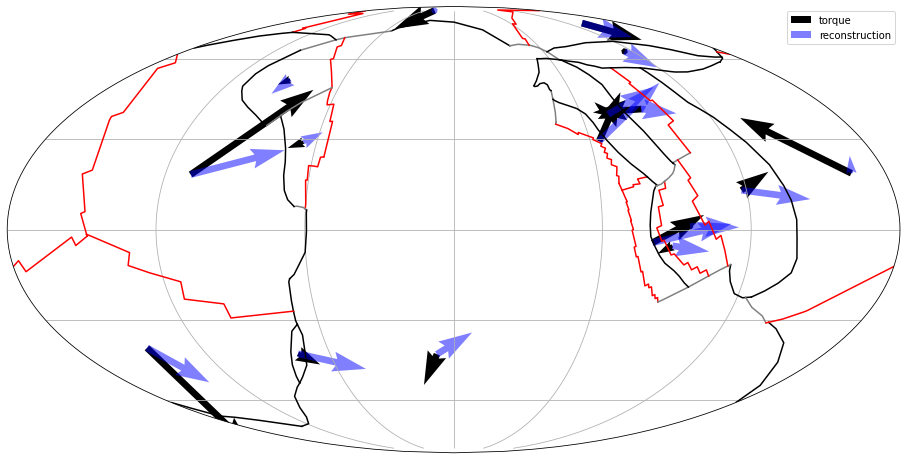

In [39]:
reconstruction_time = 290.
forces = {'slab_pull': 1,'slab_suction': 0.25, 'ridge_push':0.1}
#forces = {'ridge_push': 1}

snapshot = M2016.plate_snapshot(reconstruction_time)

result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

plate_ids = []
angles = []

for res in result:
    if res[4] is not None:
        try:
            angle = pygplates.Vector3D.angle_between(res[4],res[6])
            plate_ids.append(res[0])
            angles.append(np.degrees(angle))
        except:
            print('unable to plot vector for plate %d' % res[0])
                        
plt.figure(figsize=(16,12))
#ax = plt.axes(projection=ccrs.Orthographic(central_longitude=90.0, central_latitude=0.0))
ax = plt.axes(projection=ccrs.Mollweide(central_longitude=0.0))

for boundary in snapshot.resolved_topological_sections:
    shared_sub_segments = boundary.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        if shared_sub_segment.get_resolved_feature().get_geometry() is not None:
            if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
                boundary_color = 'black'
            elif shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_mid_ocean_ridge:
                boundary_color = 'red'
            else:
                boundary_color = 'gray'
            ax.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                    shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],
                    transform=ccrs.Geodetic(), color=boundary_color)


# plot the predicted velocities
x = []; y = []; u = []; v = []
for point,vel in zip(list(zip(*result))[1],
                     list(zip(*result))[4]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='black', label='torque')

# plot velocities according to the reconstruction
x = []; y = []; u = []; v = []
for point,vel in zip(list(zip(*result))[1],
                     list(zip(*result))[6]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='blue', alpha=0.5, label='reconstruction')

ax.set_global()
ax.gridlines()
plt.legend()
plt.show()

In [73]:
import pygmt

reconstruction_time = 250.
forces = {'slab_pull': 1,'slab_suction': 0.25}#, 'ridge_push':0.1}



def plot_torques(reconstruction_time, forces, show=True, fig=None):
    
    snapshot = M2016.plate_snapshot(reconstruction_time)
    reconstructed_continents = M2016.polygon_snapshot('continents', reconstruction_time)
    
    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)
    
    plate_ids = []
    angles = []

    for res in result:
        if res[4] is not None:
            try:
                angle = pygplates.Vector3D.angle_between(res[4],res[6])
                plate_ids.append(res[0])
                angles.append(np.degrees(angle))
            except:
                print('unable to plot vector for plate %d' % res[0])

    if not fig:
        fig = pygmt.Figure()
    #fig.basemap(region='-90/270/-90/90', projection='W6i', frame='afg')
    fig.basemap(region='g', projection='G110/10/10c', frame='afg')
    reconstructed_continents.plot(fig, fill_color='wheat')
    snapshot.plot_subduction_zones(fig)
    snapshot.plot_mid_ocean_ridges(fig)
    snapshot.plot_other_boundaries(fig)

    # plot the predicted velocities
    vector_list = []
    for point,vel in zip(list(zip(*result))[1],
                         list(zip(*result))[4]):
        if vel is not None:
            vector_list.append([point.to_lat_lon()[1],
                               point.to_lat_lon()[0],
                               np.degrees(np.arctan2(vel.get_x(),vel.get_y())),
                               vel.get_magnitude()*2.])
    fig.plot(data=vector_list, style="v0.4c+e", pen="1p,darkred", color="red")

    # plot velocities according to the reconstruction
    vector_list = []
    for point,vel in zip(list(zip(*result))[1],
                         list(zip(*result))[6]):
        if vel is not None:
            vector_list.append([point.to_lat_lon()[1],
                               point.to_lat_lon()[0],
                               np.degrees(np.arctan2(vel.get_x(),vel.get_y())),
                               vel.get_magnitude()/100.])
    fig.plot(data=vector_list, style="v0.4c+e", pen="1p,darkblue", color="dodgerblue")

    if show:
        fig.show(width=700)
    else:
        return fig


unable to plot vector for plate 496


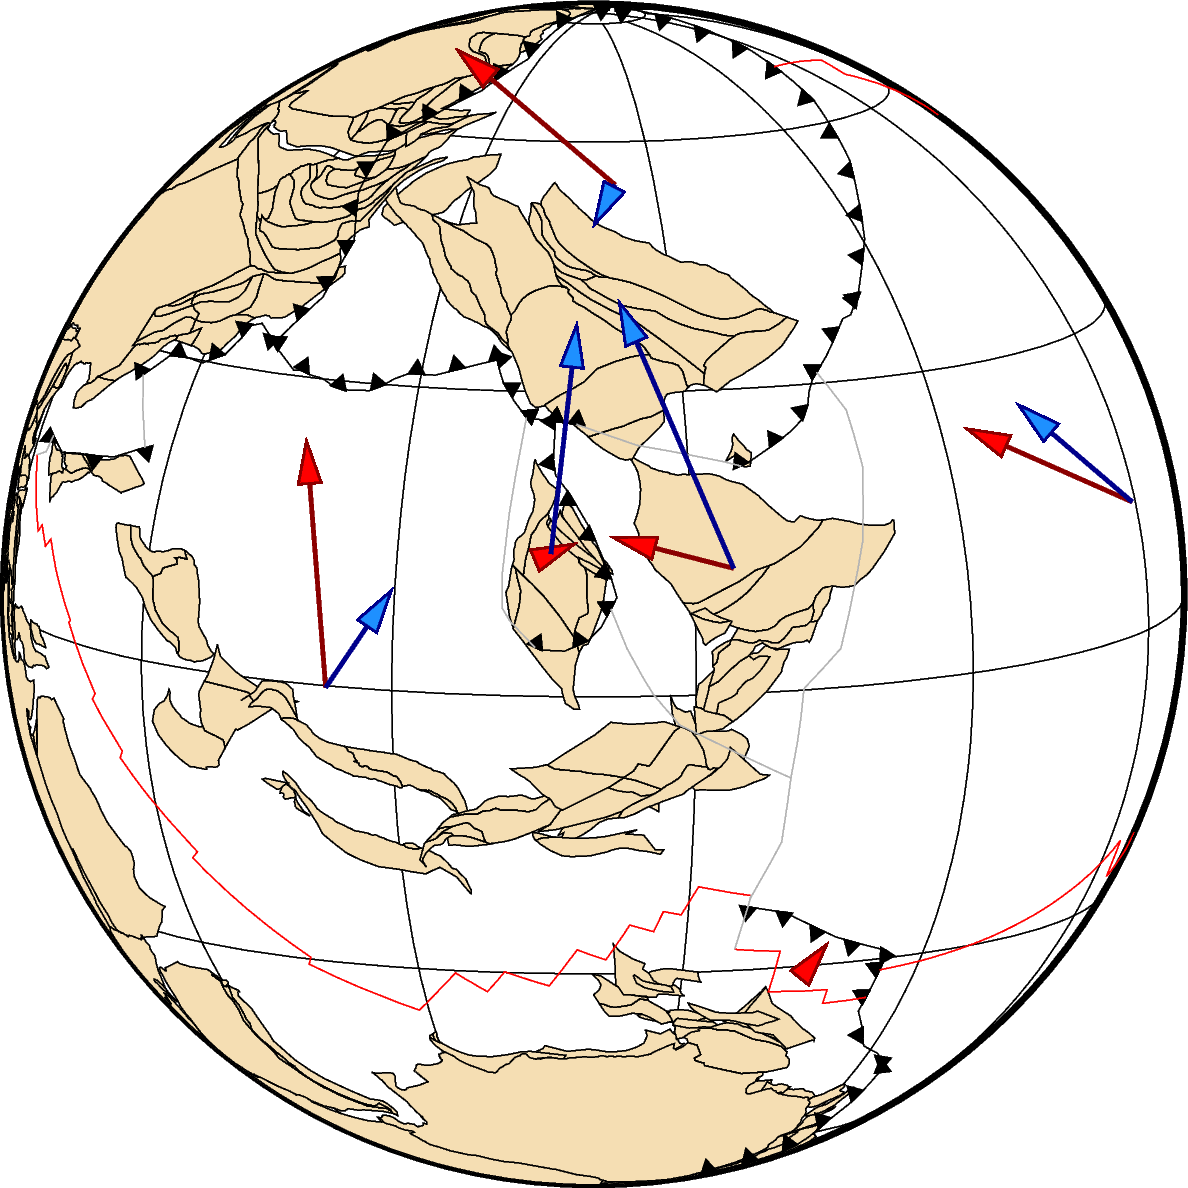

In [74]:
reconstruction_time = 250.
forces = {'slab_pull': 1,'slab_suction': 0.25}#, 'ridge_push':0.1}

fig = plot_torques(reconstruction_time, forces, show=False)
fig.show(width=700)

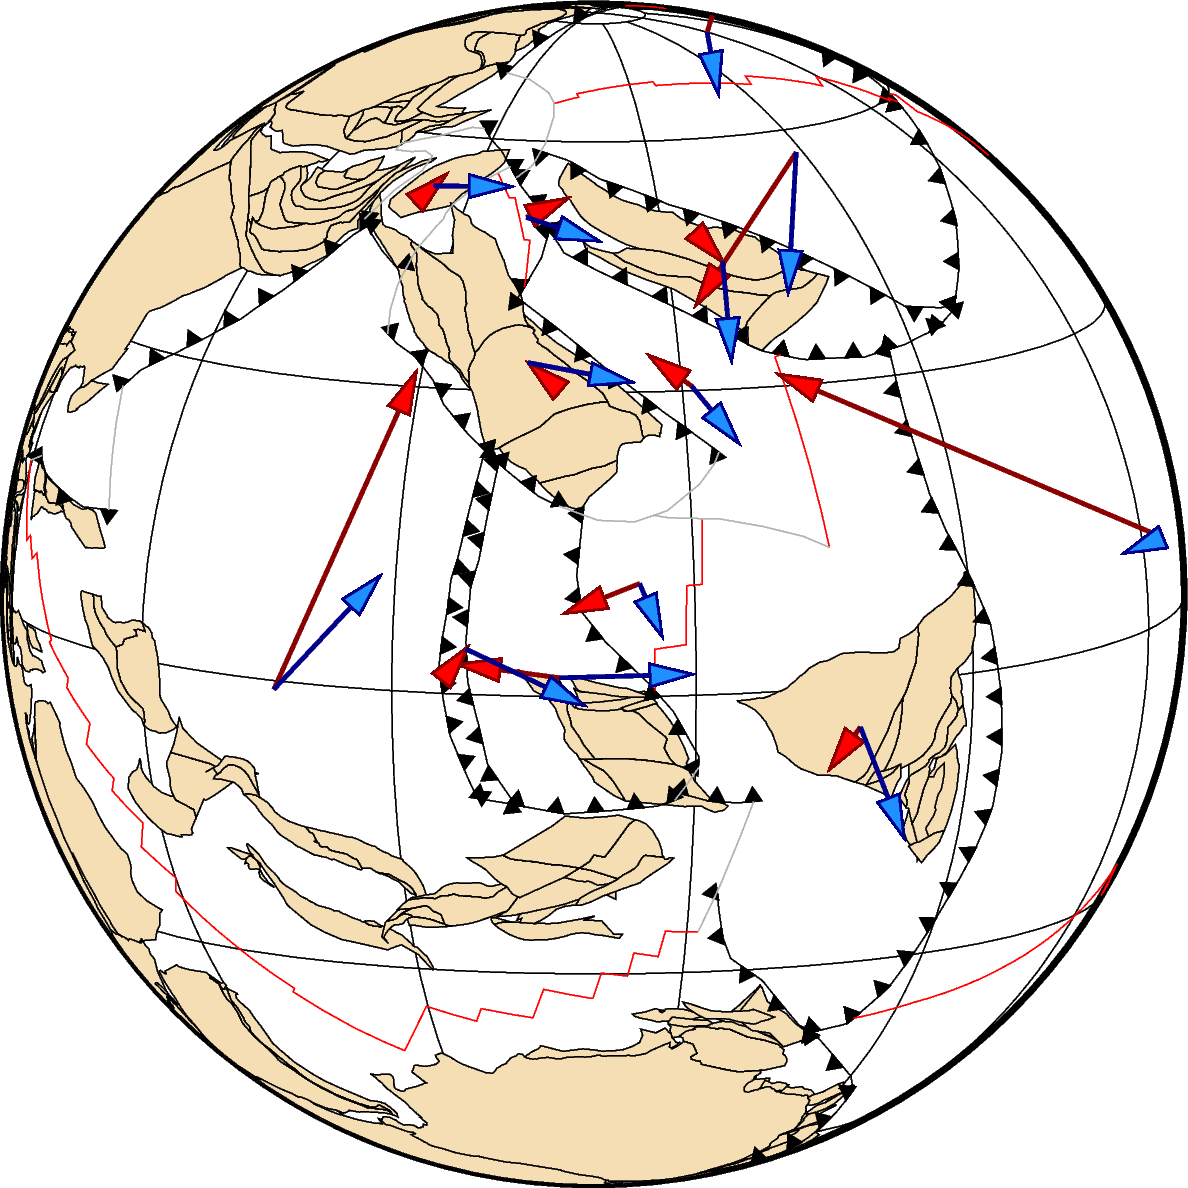

In [75]:
reconstruction_time = 260.
forces = {'slab_pull': 1,'slab_suction': 0.25}#, 'ridge_push':0.1}

fig = plot_torques(reconstruction_time, forces, show=False)
fig.show(width=700)

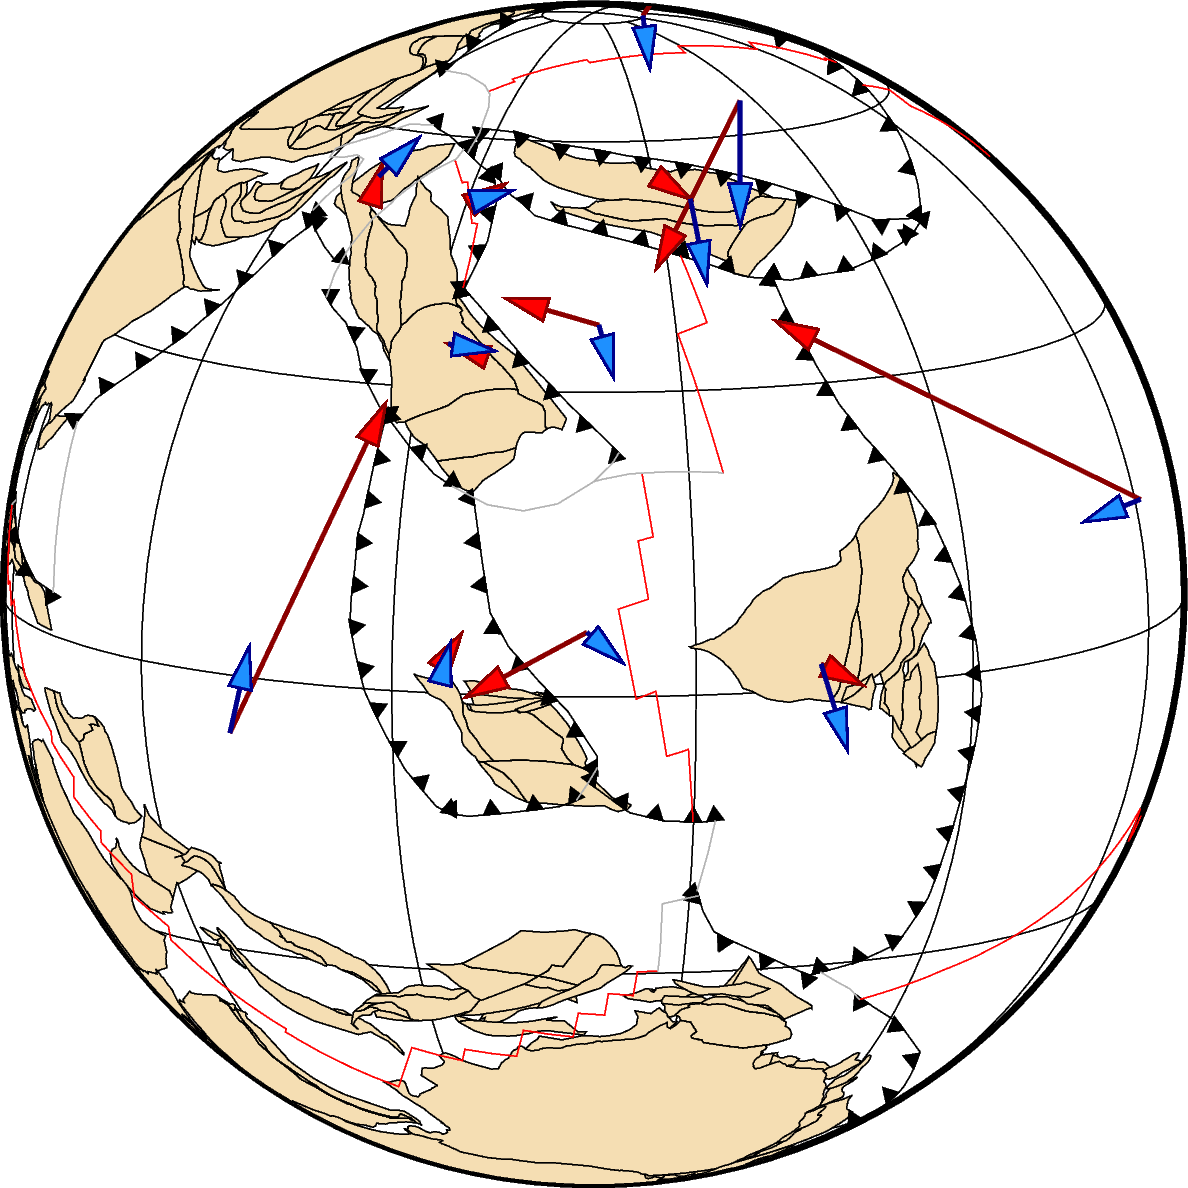

In [76]:
reconstruction_time = 270.
forces = {'slab_pull': 1,'slab_suction': 0.25}#, 'ridge_push':0.1}

fig = plot_torques(reconstruction_time, forces, show=False)
fig.show(width=700)